<a href="https://colab.research.google.com/github/pngan-web/quan-ly-khach-hang/blob/main/L06_Nhom08_QuanLyKhachHangProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CẤU TRÚC DỮ LIỆU TÀI CHÍNH &amp; GIẢI THUẬT
---
## BÁO CÁO ĐỒ ÁN - ĐỀ TÀI 6:
# XÂY DỰNG CHƯƠNG TRÌNH QUẢN LÝ THÔNG TIN KHÁCH HÀNG NGÂN HÀNG
---
### MỤC LỤC CÁC Ô
| Ô  | Nội dung  | Cấu trúc dữ liệu &amp; Giải thuật áp dụng |
| :--- | :--- | :--- |
| Ô 1 | Cài đặt Cấu trúc dữ liệu &amp; Giải thuật cốt lõi | Trie, Merge Sort, Binary Search, Hash Table (\`dict\`), Set, Stack, Heap |
| Ô 2 | Demo 5 nghiệp vụ thực tế (1.000 hồ sơ) | Tra cứu O(1), Gợi ý Trie O(L), Top-K Heap, Undo Stack |
| Ô 3 | Kiểm thử tự động (Unit Test) | 24 ca kiểm thử độc lập (TC01 - TC24) bao phủ dữ liệu biên |
| Ô 4 | Thực nghiệm &amp; Đo lường hiệu năng | Benchmark đa quy mô (n = 100, 1.000, 10.000) bằng \`time\` &amp; \`tracemalloc\` |
| Ô 5 | Trực quan hóa dữ liệu hiệu năng | Vẽ đồ thị so sánh thang log-scale bằng \`matplotlib\` |
| Ô 6 | Giao diện điều khiển (Console Menu) | Menu tương tác 10 chức năng cho người dùng thao tác trực tiếp |

## 1. Cài đặt cấu trúc dữ liệu và giải thuật

In [5]:
# @title
# ============================================================================
# Ô 1.1: THƯ VIỆN & CẤU TRÚC DỮ LIỆU NÂNG CAO: CÂY TIỀN TỐ (TRIE) [CHƯƠNG 1 & 3]
# ============================================================================
import csv
import heapq
import random
import re
import unicodedata
from datetime import date, timedelta

# 1. TIỆN ÍCH CHUẨN HÓA DỮ LIỆU
def bo_dau(s):
    """Chuyển chuỗi tiếng Việt về chữ thường không dấu: 'Nguyễn Văn Ân' -> 'nguyen van an'."""
    s = s.replace("đ", "d").replace("Đ", "D")
    s = unicodedata.normalize("NFD", s)
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return " ".join(s.lower().split())

EMAIL_RE = re.compile(r"^[\w.+-]+@[\w-]+(\.[\w-]+)+$")
LOAI_HOP_LE = {"Thường", "VIP", "Doanh nghiệp"}

# 2. CẤU TRÚC CÂY TIỀN TỐ (TRIE) TỰ CÀI ĐẶT
class TrieNode:
    __slots__ = ("con", "ds_ma")
    def __init__(self):
        self.con = {}  # Ký tự -> TrieNode
        self.ds_ma = set()  # Tập hợp mã KH đi qua nút này để gợi ý tức thì

class Trie:
    """Cây tiền tố (Trie): tìm các mã KH có họ tên bắt đầu bằng một tiền tố, O(L)."""
    def __init__(self):
        self.goc = TrieNode()

    def chen(self, khoa, ma_kh):
        nut = self.goc
        for ch in khoa:
            nut = nut.con.setdefault(ch, TrieNode())
            nut.ds_ma.add(ma_kh)

    def xoa(self, khoa, ma_kh):
        nut = self.goc
        for ch in khoa:
            if ch not in nut.con:
                return
            nut = nut.con[ch]
            nut.ds_ma.discard(ma_kh)

    def tim_tien_to(self, tien_to):
        nut = self.goc
        for ch in tien_to:
            if ch not in nut.con:
                return set()
            nut = nut.con[ch]
        return set(nut.ds_ma)

In [6]:
# @title
# ============================================================================
# Ô 1.2: GIẢI THUẬT SẮP XẾP & TÌM KIẾM [CHƯƠNG 4]
# ============================================================================

def sap_xep_tron(ds, key, reverse=False):
    """Merge Sort tự cài đặt, ổn định O(n log n); trả về danh sách MỚI."""
    if len(ds) <= 1:
        return list(ds)
    giua = len(ds) // 2
    trai = sap_xep_tron(ds[:giua], key, reverse)
    phai = sap_xep_tron(ds[giua:], key, reverse)
    kq, i, j = [], 0, 0
    while i < len(trai) and j < len(phai):
        a, b = key(trai[i]), key(phai[j])
        lay_trai = (a >= b) if reverse else (a <= b)  # Dấu '=' đảm bảo tính ổn định (Stable Sort)
        if lay_trai:
            kq.append(trai[i])
            i += 1
        else:
            kq.append(phai[j])
            j += 1
    kq.extend(trai[i:])
    kq.extend(phai[j:])
    return kq

def sap_xep_chen(ds, key, reverse=False):
    """Insertion Sort, O(n^2) – dùng làm mốc đối chứng khi đo hiệu năng."""
    a = list(ds)
    for i in range(1, len(a)):
        x, kx = a[i], key(a[i])
        j = i - 1
        while j >= 0 and ((key(a[j]) < kx) if reverse else (key(a[j]) > kx)):
            a[j + 1] = a[j]
            j -= 1
        a[j + 1] = x
    return a

def tim_tuan_tu(ds, ma_kh):
    """Linear Search duyệt tuần tự qua mảng, O(n)."""
    for kh in ds:
        if kh["ma_kh"] == ma_kh:
            return kh
    return None

def tim_nhi_phan(ds_da_sap_theo_ma, ma_kh):
    """
    Binary Search tự cài đặt theo giải thuật Chương 4, O(log n).
    Yêu cầu: ds_da_sap_theo_ma đã được sắp tăng dần theo 'ma_kh'.
    """
    trai = 0
    phai = len(ds_da_sap_theo_ma) - 1
    while trai <= phai:
        giua = (trai + phai) // 2
        ma_giua = ds_da_sap_theo_ma[giua]["ma_kh"]
        if ma_giua == ma_kh:
            return ds_da_sap_theo_ma[giua]
        elif ma_giua < ma_kh:
            trai = giua + 1
        else:
            phai = giua - 1
    return None

def trung_hai_vong_lap(ds):
    """Phát hiện CCCD trùng bằng 2 vòng lặp lồng nhau, O(n^2)."""
    trung = []
    for i in range(len(ds)):
        for j in range(i + 1, len(ds)):
            if ds[i]["cccd"] == ds[j]["cccd"]:
                trung.append((ds[i]["ma_kh"], ds[j]["ma_kh"]))
    return trung

def trung_bang_set(ds):
    """Phát hiện CCCD trùng bằng cấu trúc tập hợp Set, O(n)."""
    da_thay, trung = {}, []
    for kh in ds:
        if kh["cccd"] in da_thay:
            trung.append((da_thay[kh["cccd"]], kh["ma_kh"]))
        else:
            da_thay[kh["cccd"]] = kh["ma_kh"]
    return trung

In [4]:
# @title
# ============================================================================
# Ô 1.3: LỚP NGHIỆP VỤ QUẢN LÝ KHÁCH HÀNG & TIỆN ÍCH [CHƯƠNG 1 & 2]
# ============================================================================
class QuanLyKhachHang:
    TRUONG = ["ma_kh", "ho_ten", "cccd", "sdt", "email", "dia_phuong", "loai_kh", "so_du", "ngay_dk"]

    def __init__(self):
        self.ds = []  # list : lưu toàn bộ hồ sơ theo thứ tự nhập
        self.chi_muc = {}  # dict : ma_kh -> hồ sơ, tra cứu O(1)
        self.tap_cccd, self.tap_sdt, self.tap_email = set(), set(), set()  # set: chống trùng O(1)
        self.trie = Trie()  # trie : gợi ý tìm kiếm theo tiền tố họ tên
        self.ngan_xep = []  # stack: lịch sử thao tác phục vụ hoàn tác Undo (LIFO)

    def __len__(self):
        return len(self.ds)

    @staticmethod
    def chuan_hoa(rec):
        r = dict(rec)
        r["ma_kh"] = str(r.get("ma_kh", "")).strip().upper()
        r["ho_ten"] = " ".join(str(r.get("ho_ten", "")).split())
        r["cccd"] = str(r.get("cccd", "")).strip()
        r["sdt"] = str(r.get("sdt", "")).strip()
        r["email"] = str(r.get("email", "")).strip().lower()
        r["dia_phuong"] = str(r.get("dia_phuong", "")).strip()
        r["loai_kh"] = str(r.get("loai_kh", "")).strip()
        try:
            r["so_du"] = float(r.get("so_du"))
        except (TypeError, ValueError):
            r["so_du"] = None
        return r

    def kiem_tra_hop_le(self, r):
        for tr in self.TRUONG:
            if tr not in r or r[tr] is None or r[tr] == "":
                return False, f"Thiếu trường '{tr}'"
        if not (len(r["cccd"]) == 12 and r["cccd"].isdigit()):
            return False, "CCCD phải gồm 12 chữ số"
        if not (len(r["sdt"]) == 10 and r["sdt"].isdigit() and r["sdt"].startswith("0")):
            return False, "SĐT phải gồm 10 chữ số, bắt đầu bằng 0"
        if not EMAIL_RE.match(r["email"]):
            return False, "Email không đúng định dạng"
        if r["loai_kh"] not in LOAI_HOP_LE:
            return False, "Loại khách hàng không hợp lệ"
        if r["so_du"] < 0:
            return False, "Số dư âm"
        return True, ""

    def _kiem_tra_trung(self, r, bo_qua_ma=None):
        if r["ma_kh"] in self.chi_muc and r["ma_kh"] != bo_qua_ma:
            return "Trùng mã khách hàng"
        cu = self.chi_muc.get(bo_qua_ma) if bo_qua_ma else None
        if r["cccd"] in self.tap_cccd and (not cu or r["cccd"] != cu["cccd"]):
            return "Trùng CCCD"
        if r["sdt"] in self.tap_sdt and (not cu or r["sdt"] != cu["sdt"]):
            return "Trùng số điện thoại"
        if r["email"] in self.tap_email and (not cu or r["email"] != cu["email"]):
            return "Trùng email"
        return ""

    def _chi_muc_hoa(self, r):
        self.chi_muc[r["ma_kh"]] = r
        self.tap_cccd.add(r["cccd"])
        self.tap_sdt.add(r["sdt"])
        self.tap_email.add(r["email"])
        tu = bo_dau(r["ho_ten"]).split()
        for i in range(len(tu)):
            self.trie.chen(" ".join(tu[i:]), r["ma_kh"])

    def _go_chi_muc(self, r):
        self.chi_muc.pop(r["ma_kh"], None)
        self.tap_cccd.discard(r["cccd"])
        self.tap_sdt.discard(r["sdt"])
        self.tap_email.discard(r["email"])
        tu = bo_dau(r["ho_ten"]).split()
        for i in range(len(tu)):
            self.trie.xoa(" ".join(tu[i:]), r["ma_kh"])

    def them(self, rec, ghi_undo=True):
        r = self.chuan_hoa(rec)
        ok, ly_do = self.kiem_tra_hop_le(r)
        if not ok:
            return False, ly_do
        ly_do = self._kiem_tra_trung(r)
        if ly_do:
            return False, ly_do
        self.ds.append(r)
        self._chi_muc_hoa(r)
        if ghi_undo:
            self.ngan_xep.append(("them", r["ma_kh"]))
        return True, "Đã thêm khách hàng " + r["ma_kh"]

    def tra_cuu(self, ma_kh):
        return self.chi_muc.get(str(ma_kh).strip().upper())

    def tim_theo_ten(self, tien_to):
        tien_to = bo_dau(str(tien_to))
        if not tien_to:
            return []
        tap_ma = self.trie.tim_tien_to(tien_to)
        return [self.chi_muc[m] for m in sorted(tap_ma) if m in self.chi_muc]

    def loc(self, dia_phuong=None, loai_kh=None, so_du_tu=None, so_du_den=None):
        kq = []
        for kh in self.ds:
            if dia_phuong and kh["dia_phuong"] != dia_phuong: continue
            if loai_kh and kh["loai_kh"] != loai_kh: continue
            if so_du_tu is not None and kh["so_du"] < so_du_tu: continue
            if so_du_den is not None and kh["so_du"] > so_du_den: continue
            kq.append(kh)
        return kq

    def sua(self, ma_kh, **thay_doi):
        ma_kh = str(ma_kh).strip().upper()
        cu = self.chi_muc.get(ma_kh)
        if cu is None:
            return False, "Không tìm thấy khách hàng"
        thay_doi.pop("ma_kh", None)
        moi = self.chuan_hoa({**cu, **thay_doi})
        ok, ly_do = self.kiem_tra_hop_le(moi)
        if not ok:
            return False, ly_do
        ly_do = self._kiem_tra_trung(moi, bo_qua_ma=ma_kh)
        if ly_do:
            return False, ly_do
        vi_tri = self.ds.index(cu)
        self._go_chi_muc(cu)
        self.ds[vi_tri] = moi
        self._chi_muc_hoa(moi)
        self.ngan_xep.append(("sua", dict(cu)))
        return True, "Đã cập nhật " + ma_kh

    def xoa(self, ma_kh, ghi_undo=True):
        ma_kh = str(ma_kh).strip().upper()
        cu = self.chi_muc.get(ma_kh)
        if cu is None:
            return False, "Không tìm thấy khách hàng"
        vi_tri = self.ds.index(cu)
        del self.ds[vi_tri]
        self._go_chi_muc(cu)
        if ghi_undo:
            self.ngan_xep.append(("xoa", dict(cu), vi_tri))
        return True, "Đã xóa " + ma_kh

    def hoan_tac(self):
        if not self.ngan_xep:
            return False, "Không còn thao tác để hoàn tác"
        thao_tac = self.ngan_xep.pop()
        if thao_tac[0] == "them":
            self.xoa(thao_tac[1], ghi_undo=False)
            return True, "Đã hoàn tác: thêm " + thao_tac[1]
        if thao_tac[0] == "xoa":
            _, r, vi_tri = thao_tac
            self.ds.insert(vi_tri, r)
            self._chi_muc_hoa(r)
            return True, "Đã hoàn tác: xóa " + r["ma_kh"]
        if thao_tac[0] == "sua":
            r = thao_tac[1]
            hien_tai = self.chi_muc[r["ma_kh"]]
            vi_tri = self.ds.index(hien_tai)
            self._go_chi_muc(hien_tai)
            self.ds[vi_tri] = r
            self._chi_muc_hoa(r)
            return True, "Đã hoàn tác: sửa " + r["ma_kh"]

    def sap_xep(self, theo="ho_ten", giam_dan=False):
        if theo == "ho_ten":
            def khoa(kh):
                tu = bo_dau(kh["ho_ten"]).split()
                return (tu[-1], bo_dau(kh["ho_ten"]))
        elif theo in ("so_du", "ngay_dk", "ma_kh"):
            def khoa(kh): return kh[theo]
        else:
            raise ValueError("Tiêu chí sắp xếp không hợp lệ: " + str(theo))
        return sap_xep_tron(self.ds, khoa, giam_dan)

    def top_k_so_du(self, k):
        """Top-k số dư lớn nhất bằng Heap (Priority Queue), O(n log k)."""
        if k <= 0:
            return []
        return heapq.nlargest(k, self.ds, key=lambda kh: kh["so_du"])

    def thong_ke(self, theo="loai_kh"):
        nhom = {}
        for kh in self.ds:
            m = nhom.setdefault(kh[theo], {"so_luong": 0, "tong_so_du": 0.0})
            m["so_luong"] += 1
            m["tong_so_du"] += kh["so_du"]
        return nhom

    def ghi_csv(self, duong_dan):
        with open(duong_dan, "w", newline="", encoding="utf-8-sig") as f:
            w = csv.DictWriter(f, fieldnames=self.TRUONG)
            w.writeheader()
            for kh in self.ds:
                row = dict(kh)
                row["ngay_dk"] = str(row["ngay_dk"])
                w.writerow(row)

    def doc_csv(self, duong_dan):
        them_duoc, loi = 0, []
        with open(duong_dan, newline="", encoding="utf-8-sig") as f:
            for dong, row in enumerate(csv.DictReader(f), start=2):
                try:
                    row["ngay_dk"] = date.fromisoformat(row["ngay_dk"])
                except (ValueError, KeyError):
                    loi.append((dong, "Ngày đăng ký không hợp lệ"))
                    continue
                ok, msg = self.them(row)
                if ok:
                    them_duoc += 1
                else:
                    loi.append((dong, msg))
        return them_duoc, loi

# --- CÁC HÀM SINH DỮ LIỆU & GIAO DIỆN PHỤ TRỢ ---
HO = ["Nguyễn", "Trần", "Lê", "Phạm", "Hoàng", "Huỳnh", "Phan", "Vũ", "Võ", "Đặng", "Bùi", "Đỗ", "Hồ", "Ngô", "Dương"]
DEM = ["Văn", "Thị", "Minh", "Quốc", "Thanh", "Ngọc", "Hữu", "Anh", "Gia", "Thu", "Đức", "Hoài"]
TEN = ["An", "Bình", "Châu", "Dũng", "Giang", "Hà", "Hùng", "Khánh", "Lan", "Linh", "Mai", "Nam", "Phúc", "Quân", "Sơn", "Thảo", "Trang", "Tuấn", "Vy", "Yến", "Ân", "Đạt", "Oanh", "Hiếu"]
DIA_PHUONG = ["TP. Hồ Chí Minh", "Hà Nội", "Đà Nẵng", "Cần Thơ", "Hải Phòng", "Đồng Nai", "Bình Dương", "Khánh Hòa", "Lâm Đồng", "Nghệ An"]

def sinh_du_lieu(n, hat_giong=42):
    rd = random.Random(hat_giong)
    ds = []
    ngay_dau = date(2015, 1, 1)
    so_ngay = (date(2026, 9, 30) - ngay_dau).days
    cccd_set = rd.sample(range(10**11, 10**12), n)
    sdt_set = rd.sample(range(10**8, 10**9), n)
    for i in range(n):
        ten = f"{rd.choice(HO)} {rd.choice(DEM)} {rd.choice(TEN)}"
        loai = rd.choices(["Thường", "VIP", "Doanh nghiệp"], weights=[80, 15, 5])[0]
        he_so = {"Thường": 1, "VIP": 8, "Doanh nghiệp": 25}[loai]
        so_du = round(rd.lognormvariate(16.0, 1.0) * he_so / 10) * 10
        ds.append({
            "ma_kh": f"KH{i + 1:06d}",
            "ho_ten": ten,
            "cccd": f"{cccd_set[i]:012d}",
            "sdt": f"0{sdt_set[i]:09d}",
            "email": f"{bo_dau(ten).replace(' ', '.')}.{i + 1}@mail.test",
            "dia_phuong": rd.choice(DIA_PHUONG),
            "loai_kh": loai,
            "so_du": float(so_du),
            "ngay_dk": ngay_dau + timedelta(days=rd.randrange(so_ngay)),
        })
    return ds

def nap_he_thong(ds):
    ql = QuanLyKhachHang()
    for r in ds:
        ql.them(r, ghi_undo=False)
    return ql

def vnd(x):
    return f"{x:,.0f}".replace(",", ".")

def in_bang(ds, toi_da=10):
    print(f"{'Mã KH':<10}| {'Họ tên':<20}| {'Địa phương':<16}| {'Loại':<13}| {'Số dư (đ)':>18}")
    print("-" * 82)
    for kh in ds[:toi_da]:
        print(f"{kh['ma_kh']:<10}| {kh['ho_ten']:<20}| {kh['dia_phuong']:<16}| {kh['loai_kh']:<13}| {vnd(kh['so_du']):>18}")
    if len(ds) > toi_da:
        print(f"... và {len(ds) - toi_da} khách hàng khác (tổng {len(ds)})")
    if not ds:
        print("(không có khách hàng nào)")

MENU = """
================= MENU CHƯƠNG TRÌNH =================
1. Thêm khách hàng mới
2. Hiển thị danh sách khách hàng
3. Tìm kiếm khách hàng
4. Sửa hoặc Xóa thông tin khách hàng
5. Sắp xếp danh sách
6. Top-K số dư lớn nhất
7. Thống kê số dư theo nhóm
8. Hoàn tác thao tác vừa rồi (Undo)
9. Ghi / Đọc tệp tin CSV
0. Thoát chương trình
======================================================
"""

def chay_menu(ql, nhap=input):
    while True:
        print(MENU)
        chon = nhap("Chọn chức năng: ").strip()
        if chon == "0":
            print("Kết thúc chương trình.")
            return
        elif chon == "1":
            r = {t: nhap(f"  {t}: ") for t in ["ma_kh", "ho_ten", "cccd", "sdt", "email", "dia_phuong", "loai_kh", "so_du"]}
            try:
                r["ngay_dk"] = date.fromisoformat(nhap("  ngay_dk (YYYY-MM-DD): ").strip())
            except ValueError:
                print("✗ Ngày đăng ký không hợp lệ")
                continue
            print(("✓ " if (kq := ql.them(r))[0] else "✗ ") + kq[1])
        elif chon == "2":
            in_bang(ql.ds)
        elif chon == "3":
            kieu = nhap("  Tìm theo (1) mã  (2) tên/tiền tố: ").strip()
            if kieu == "1":
                kh = ql.tra_cuu(nhap("  Mã KH: "))
                in_bang([kh] if kh else [])
            else:
                in_bang(ql.tim_theo_ten(nhap("  Tiền tố họ tên: ")))
        elif chon == "4":
            ma = nhap("  Mã KH: ")
            hd = nhap("  (s) sửa số dư  (x) xóa: ").strip().lower()
            if hd == "x":
                print(ql.xoa(ma)[1])
            else:
                print(ql.sua(ma, so_du=nhap("  Số dư mới: "))[1])
        elif chon == "5":
            tc_ = nhap("  Theo (ho_ten / so_du / ngay_dk / ma_kh): ").strip()
            gd = nhap("  Giảm dần? (c/k): ").strip().lower() == "c"
            try:
                in_bang(ql.sap_xep(tc_, gd))
            except ValueError as e:
                print("✗", e)
        elif chon == "6":
            try:
                in_bang(ql.top_k_so_du(int(nhap("  k = "))))
            except ValueError:
                print("✗ k phải là số nguyên")
        elif chon == "7":
            for nhom, v in ql.thong_ke(nhap("  Theo (loai_kh / dia_phuong): ").strip() or "loai_kh").items():
                print(f"  {nhom:<16}: {v['so_luong']:>5} KH | tổng số dư {vnd(v['tong_so_du'])} đ")
        elif chon == "8":
            print(ql.hoan_tac()[1])
        elif chon == "9":
            hd = nhap("  (g) ghi  (d) đọc: ").strip().lower()
            dd = nhap("  Đường dẫn file: ").strip()
            try:
                if hd == "g":
                    ql.ghi_csv(dd)
                    print("✓ Đã ghi", dd)
                else:
                    n, loi = ql.doc_csv(dd)
                    print(f"✓ Thêm {n} KH; {len(loi)} dòng lỗi", loi[:3])
            except OSError as e:
                print("✗ Lỗi tệp:", e)
        else:
            print("✗ Lựa chọn không hợp lệ")

## 2. Demo nhanh

In [ ]:
# @title
# ============================================================================
# Ô 2: KỊCH BẢN DEMO THỰC THI (5 BƯỚC THUYẾT TRÌNH TRÊN 1.000 HỒ SƠ)
# ============================================================================
ql = nap_he_thong(sinh_du_lieu(1000))

print("=== 1. TRA CỨU TỨC THÌ O(1) BẰNG BẢNG BĂM (DICT) ===")
kh = ql.tra_cuu("KH000123")
print(f"Mã: {kh['ma_kh']} | Tên: {kh['ho_ten']} | SĐT: {kh['sdt']} | Số dư: {vnd(kh['so_du'])} đ")

print("\n=== 2. TÌM GỢI Ý TÊN BẰNG CÂY TIỀN TỐ (TRIE) ===")
print("Gợi ý từ khóa 'tran thi':")
in_bang(ql.tim_theo_ten("tran thi"), toi_da=4)

print("\n=== 3. TRÍCH XUẤT TOP-5 SỐ DƯ CAO NHẤT (HEAP O(n log k)) ===")
in_bang(ql.top_k_so_du(5))

print("\n=== 4. SẮP XẾP DANH SÁCH BẰNG MERGE SORT O(n log n) ===")
in_bang(ql.sap_xep("ho_ten"), toi_da=5)

print("\n=== 5. KIỂM SOÁT TÍNH TOÀN VẸN & HOÀN TÁC (UNDO BẰNG STACK) ===")
ok1, msg1 = ql.them({
    "ma_kh": "KH001001",
    "ho_ten": "Lê Thị Hoa",
    "cccd": "079312345678",
    "sdt": "0912345678",
    "email": "hoa.le@mail.test",
    "dia_phuong": "Đà Nẵng",
    "loai_kh": "VIP",
    "so_du": 250000000,
    "ngay_dk": date(2026, 9, 1)
})
print("Thêm mới:", msg1)

ok2, msg2 = ql.them({
    "ma_kh": "KH001001",
    "ho_ten": "Người Trùng",
    "cccd": "079312345699",
    "sdt": "0912345699",
    "email": "trung@mail.test",
    "dia_phuong": "Hà Nội",
    "loai_kh": "Thường",
    "so_du": 100000,
    "ngay_dk": date(2026, 9, 1)
})
print("Thử thêm trùng mã:", msg2)

ok_undo, msg_undo = ql.hoan_tac()
print("Hoàn tác Undo:", msg_undo)
print(f"Tổng số hồ sơ sau hoàn tác: {len(ql)} (vẫn bảo toàn đúng 1.000 hồ sơ)")

## 3. Kiểm thử chức năng (24 ca)
Mỗi ca kiểm thử bắt ngoại lệ để một ca lỗi không làm dừng cả bộ kiểm thử.

In [7]:
# @title
KQ = {'test': [], 'perf': {}, 'demo': {}}
# -*- coding: utf-8 -*-
import json, random, time, statistics, os
from datetime import date


def mau(i=1, **kw):
    r = {"ma_kh": f"KH{i:06d}", "ho_ten": "Nguyễn Văn An", "cccd": f"0790{i:08d}",
         "sdt": f"09{i:08d}", "email": f"an{i}@mail.test", "dia_phuong": "Hà Nội",
         "loai_kh": "Thường", "so_du": 1_000_000, "ngay_dk": date(2024, 1, 15)}
    r.update(kw); return r

def tc(ma, mo_ta, dau_vao, mong_doi, ham):
    try:
        thuc_te = ham()
        dat = bool(thuc_te[0])
        KQ["test"].append({"ma": ma, "mo_ta": mo_ta, "dau_vao": dau_vao, "mong_doi": mong_doi,
                           "thuc_te": thuc_te[1], "dat": dat})
    except Exception as e:                      # test không được phép làm chương trình dừng
        KQ["test"].append({"ma": ma, "mo_ta": mo_ta, "dau_vao": dau_vao, "mong_doi": mong_doi,
                           "thuc_te": "Lỗi: " + repr(e), "dat": False})

# ---- nhóm A: thêm / kiểm tra hợp lệ / trùng ----
def t01():
    ql = QuanLyKhachHang()
    return (len(ql.ds) == 0 and ql.tra_cuu("KH000001") is None and ql.sap_xep() == []
            and ql.top_k_so_du(3) == [] and ql.tim_theo_ten("n") == [] and ql.thong_ke() == {}
            and ql.hoan_tac()[0] is False), "Mọi thao tác trên danh sách rỗng đều trả về rỗng/None, không phát sinh lỗi"
tc("TC01", "Danh sách rỗng", "Hệ thống chưa có khách hàng; gọi tra cứu, sắp xếp, Top-k, tìm tiền tố, thống kê, hoàn tác",
   "Không phát sinh lỗi; kết quả rỗng/None", t01)

def t02():
    ql = QuanLyKhachHang(); ok, m = ql.them(mau(1))
    return (ok and len(ql) == 1 and ql.sap_xep()[0]["ma_kh"] == "KH000001"
            and ql.top_k_so_du(5)[0]["ma_kh"] == "KH000001" and tim_nhi_phan(ql.ds, "KH000001") is not None), m + "; sắp xếp, Top-5, tìm nhị phân đều trả về đúng 1 bản ghi"
tc("TC02", "Chỉ có một phần tử", "Thêm 1 khách hàng rồi sắp xếp, Top-5, tìm nhị phân",
   "Trả về đúng 1 bản ghi", t02)

def t03():
    ql = QuanLyKhachHang(); ql.them(mau(1))
    ok, m = ql.them(mau(1, cccd="079099999999", sdt="0911111111", email="khac@mail.test"))
    return (not ok and m == "Trùng mã khách hàng" and len(ql) == 1), f"Từ chối: '{m}'; số bản ghi vẫn = {len(ql)}"
tc("TC03", "Trùng mã khách hàng", "Thêm KH000001 lần thứ hai (các trường khác khác biệt)", "Từ chối, báo trùng mã", t03)

def t04():
    ql = QuanLyKhachHang(); ql.them(mau(1))
    ok, m = ql.them(mau(2, cccd=mau(1)["cccd"]))
    return (not ok and m == "Trùng CCCD"), f"Từ chối: '{m}'"
tc("TC04", "Trùng CCCD", "Thêm KH000002 có CCCD trùng KH000001", "Từ chối, báo trùng CCCD", t04)

def t05():
    ql = QuanLyKhachHang(); ql.them(mau(1))
    ok1, m1 = ql.them(mau(2, sdt=mau(1)["sdt"]))
    ok2, m2 = ql.them(mau(3, email=mau(1)["email"].upper()))
    return (not ok1 and m1 == "Trùng số điện thoại" and not ok2 and m2 == "Trùng email"), f"SĐT: '{m1}'; email viết hoa: '{m2}' (được chuẩn hóa chữ thường trước khi so sánh)"
tc("TC05", "Trùng SĐT và trùng email", "SĐT trùng; email trùng nhưng viết HOA", "Từ chối cả hai, đúng lý do", t05)

def t06():
    ql = QuanLyKhachHang()
    ok, m = ql.them(mau(1, so_du=-500_000))
    return (not ok and m == "Số dư âm" and len(ql) == 0), f"Từ chối: '{m}'"
tc("TC06", "Số dư âm (giá trị không hợp lệ)", "so_du = -500.000", "Từ chối, báo số dư âm", t06)

def t07():
    ql = QuanLyKhachHang()
    kq = [ql.them(mau(1, cccd="12345"))[1], ql.them(mau(2, sdt="123"))[1],
          ql.them(mau(3, email="abc"))[1], ql.them(mau(4, loai_kh="Khác"))[1],
          ql.them(mau(5, ho_ten=""))[1], ql.them(mau(6, so_du="abc"))[1]]
    dung = ["CCCD phải gồm 12 chữ số", "SĐT phải gồm 10 chữ số, bắt đầu bằng 0", "Email không đúng định dạng",
            "Loại khách hàng không hợp lệ", "Thiếu trường 'ho_ten'", "Thiếu trường 'so_du'"]
    return (kq == dung and len(ql) == 0), "Từ chối đủ 6 trường hợp: " + " | ".join(kq)
tc("TC07", "Dữ liệu sai định dạng / thiếu", "CCCD 5 số; SĐT 3 số; email 'abc'; loại 'Khác'; họ tên rỗng; số dư 'abc'",
   "Từ chối, báo đúng từng lý do", t07)

def t08():
    ql = QuanLyKhachHang()
    ok, m = ql.them(mau(1, ma_kh="  kh000001 ", ho_ten="  Nguyễn   Văn  An ", email="AN1@Mail.TEST"))
    kh = ql.tra_cuu("kh000001")
    return (ok and kh["ma_kh"] == "KH000001" and kh["ho_ten"] == "Nguyễn Văn An" and kh["email"] == "an1@mail.test"), f"Đã chuẩn hóa: mã='{kh['ma_kh']}', họ tên='{kh['ho_ten']}', email='{kh['email']}'"
tc("TC08", "Chuẩn hóa dữ liệu nhập", "Mã '  kh000001 ' (thừa khoảng trắng, chữ thường); họ tên thừa khoảng trắng; email có chữ hoa",
   "Lưu dạng chuẩn hóa", t08)

# ---- nhóm B: tra cứu ----
def t09():
    ql = nap_he_thong(sinh_du_lieu(100)); kh = ql.tra_cuu("KH000050")
    return (kh is not None and kh["ma_kh"] == "KH000050" and tim_tuan_tu(ql.ds, "KH000050") is kh), f"Trả về {kh['ma_kh']} – {kh['ho_ten']}; kết quả dict và Linear Search trùng nhau"
tc("TC09", "Mã tồn tại", "Tra cứu KH000050 trong 100 hồ sơ", "Trả về đúng hồ sơ", t09)

def t10():
    ql = nap_he_thong(sinh_du_lieu(100)); s = sorted(ql.ds, key=lambda k: k["ma_kh"])
    a, b, c = ql.tra_cuu("KH999999"), tim_tuan_tu(ql.ds, "KH999999"), tim_nhi_phan(s, "KH999999")
    return (a is None and b is None and c is None), f"dict → {a}; Linear Search → {b}; Binary Search → {c}"
tc("TC10", "Khóa không tồn tại", "Tra cứu KH999999 bằng 3 phương pháp", "Cả ba trả về None", t10)

def t11():
    ql = nap_he_thong(sinh_du_lieu(1000)); s = sorted(ql.ds, key=lambda k: k["ma_kh"])
    ok = all(tim_nhi_phan(s, k["ma_kh"]) is k for k in ql.ds)
    ok2 = all(ql.tra_cuu(k["ma_kh"]) is k for k in ql.ds)
    return (ok and ok2), "1.000/1.000 mã đều được tìm thấy đúng bởi cả Binary Search và dict (kể cả phần tử đầu và cuối)"
tc("TC11", "Đối chiếu 3 phương pháp tra cứu", "Mọi mã trong 1.000 hồ sơ", "Binary Search = dict = Linear Search", t11)

def t12():
    ql = QuanLyKhachHang()
    for i, ten in enumerate(["Nguyễn Văn An", "Trần Thị Ân", "Lê Minh Anh", "Phạm Quốc Bình", "Đặng Hoài An"], start=1):
        ql.them(mau(i, ho_ten=ten))
    a = [k["ho_ten"] for k in ql.tim_theo_ten("an")]
    b = [k["ho_ten"] for k in ql.tim_theo_ten("NGUYỄN")]
    c = [k["ho_ten"] for k in ql.tim_theo_ten("zzz")]
    d = [k["ho_ten"] for k in ql.tim_theo_ten("van an")]
    ok = (a == ["Nguyễn Văn An", "Trần Thị Ân", "Lê Minh Anh", "Đặng Hoài An"] and b == ["Nguyễn Văn An"]
          and c == [] and d == ["Nguyễn Văn An"])
    return ok, f"'an' → {len(a)} KH (An, Ân, Anh đều khớp do bỏ dấu); 'NGUYỄN' → {b}; 'zzz' → {c}; 'van an' → {d}"
tc("TC12", "Gợi ý theo tiền tố (Trie)", "Tiền tố 'an', 'NGUYỄN', 'zzz', 'van an' trên 5 họ tên có dấu",
   "Không phân biệt hoa/thường, dấu; không khớp → rỗng", t12)

def t13():
    ql = QuanLyKhachHang()
    ql.them(mau(1, dia_phuong="Hà Nội", loai_kh="VIP", so_du=500_000_000))
    ql.them(mau(2, dia_phuong="Hà Nội", loai_kh="Thường", so_du=10_000_000))
    ql.them(mau(3, dia_phuong="Đà Nẵng", loai_kh="VIP", so_du=200_000_000))
    a = [k["ma_kh"] for k in ql.loc(dia_phuong="Hà Nội", loai_kh="VIP")]
    b = [k["ma_kh"] for k in ql.loc(so_du_tu=100_000_000, so_du_den=300_000_000)]
    c = ql.loc(dia_phuong="Cần Thơ")
    return (a == ["KH000001"] and b == ["KH000003"] and c == []), f"Hà Nội+VIP → {a}; số dư 100–300 triệu → {b}; Cần Thơ → {c}"
tc("TC13", "Lọc đa điều kiện", "(Hà Nội, VIP); số dư 100–300 triệu; địa phương không có KH", "Trả về đúng tập hợp", t13)

# ---- nhóm C: sắp xếp ----
def t14():
    ql = nap_he_thong(sinh_du_lieu(500))
    tang = ql.sap_xep("so_du"); giam = ql.sap_xep("so_du", giam_dan=True)
    ok = (all(tang[i]["so_du"] <= tang[i+1]["so_du"] for i in range(len(tang)-1))
          and all(giam[i]["so_du"] >= giam[i+1]["so_du"] for i in range(len(giam)-1))
          and [k["so_du"] for k in tang] == sorted(k["so_du"] for k in ql.ds))
    return ok, "Tăng dần/giảm dần đúng thứ tự và trùng với sorted() của Python"
tc("TC14", "Sắp xếp theo số dư (dữ liệu ngẫu nhiên)", "500 hồ sơ, tăng dần và giảm dần", "Đúng thứ tự, khớp sorted()", t14)

def t15():
    ql = nap_he_thong(sinh_du_lieu(300)); ds0 = [k["ma_kh"] for k in ql.ds]
    da_sap = ql.sap_xep("ma_kh"); ql2 = QuanLyKhachHang()
    for k in da_sap: ql2.them(k, ghi_undo=False)
    xuoi = ql2.sap_xep("ma_kh"); nguoc = sap_xep_tron(da_sap[::-1], key=lambda k: k["ma_kh"])
    ok = ([k["ma_kh"] for k in xuoi] == [k["ma_kh"] for k in da_sap]
          and [k["ma_kh"] for k in nguoc] == [k["ma_kh"] for k in da_sap]
          and [k["ma_kh"] for k in ql.ds] == ds0)
    return ok, "Dữ liệu đã có thứ tự và dữ liệu thứ tự ngược đều cho kết quả đúng; danh sách gốc không bị thay đổi"
tc("TC15", "Dữ liệu đã có thứ tự / thứ tự ngược", "300 hồ sơ đã sắp theo mã; đảo ngược rồi sắp lại", "Kết quả đúng; dữ liệu gốc giữ nguyên", t15)

def t16():
    ql = QuanLyKhachHang()
    for i, ten in enumerate(["Trần Văn Bình", "Nguyễn Thị An", "Đặng Quốc An", "Lê Minh Ân", "Phạm Hoài Anh"], start=1):
        ql.them(mau(i, ho_ten=ten))
    kq = [k["ho_ten"] for k in ql.sap_xep("ho_ten")]
    dung = ["Đặng Quốc An", "Lê Minh Ân", "Nguyễn Thị An", "Phạm Hoài Anh", "Trần Văn Bình"]
    return kq == dung, "Thứ tự: " + " → ".join(kq)
tc("TC16", "Sắp xếp theo tên (tiếng Việt)", "5 họ tên có dấu, cùng tên 'An'/'Ân'", "Xếp theo tên gọi rồi họ tên đầy đủ, không dấu", t16)

def t17():
    ql = QuanLyKhachHang()
    for i, (m, sd) in enumerate([("A", 100), ("B", 100), ("C", 50), ("D", 100)], start=1):
        ql.them(mau(i, ho_ten=f"Nguyễn Văn {m}", so_du=sd))
    kq = [k["ma_kh"] for k in ql.sap_xep("so_du", giam_dan=True)]
    return kq == ["KH000001", "KH000002", "KH000004", "KH000003"], f"Giảm dần theo số dư, ba KH cùng số dư 100 giữ thứ tự nhập: {kq}"
tc("TC17", "Giá trị trùng khi sắp xếp (tính ổn định)", "3 KH cùng số dư 100 và 1 KH số dư 50", "Giữ nguyên thứ tự nhập giữa các KH cùng số dư", t17)

def t18():
    ql = nap_he_thong(sinh_du_lieu(2000)); top = ql.top_k_so_du(5)
    chuan = sorted(ql.ds, key=lambda k: k["so_du"], reverse=True)[:5]
    ql_nho = QuanLyKhachHang(); ql_nho.them(mau(1)); ql_nho.them(mau(2, ho_ten="B"))
    return ([k["ma_kh"] for k in top] == [k["ma_kh"] for k in chuan] and len(ql.top_k_so_du(0)) == 0
            and len(ql_nho.top_k_so_du(10)) == 2), "Top-5 trùng với sắp xếp toàn bộ; k=0 → rỗng; k lớn hơn n → trả về n bản ghi"
tc("TC18", "Top-k bằng heap", "k=5 trên 2.000 hồ sơ; k=0; k=10 trên 2 hồ sơ", "Đúng thứ tự, xử lý k biên", t18)

# ---- nhóm D: sửa/xóa/hoàn tác/thống kê/CSV ----
def t19():
    ql = QuanLyKhachHang()
    for i in (1, 2, 3): ql.them(mau(i, ho_ten=f"Nguyễn Văn {'ABC'[i-1]}"))
    ok1, _ = ql.sua("KH000002", so_du=9_999_999, loai_kh="VIP")
    ok2, m2 = ql.sua("KH000002", cccd=mau(1)["cccd"])
    ok3, m3 = ql.sua("KH000099", so_du=1)
    ok4, _ = ql.sua("KH000002", cccd=mau(2)["cccd"])      # giữ nguyên CCCD của chính mình: được phép
    kh = ql.tra_cuu("KH000002")
    return (ok1 and not ok2 and m2 == "Trùng CCCD" and not ok3 and ok4 and kh["so_du"] == 9_999_999 and kh["loai_kh"] == "VIP"), f"Sửa hợp lệ → được; sửa sang CCCD của người khác → '{m2}'; sửa mã không tồn tại → '{m3}'"
tc("TC19", "Sửa hồ sơ", "Sửa số dư/loại; sửa CCCD trùng người khác; sửa mã không tồn tại; giữ nguyên CCCD của chính mình",
   "Chỉ chấp nhận thay đổi hợp lệ", t19)

def t20():
    ql = QuanLyKhachHang(); ql.them(mau(1, ho_ten="Nguyễn Văn An")); ql.them(mau(2, ho_ten="Trần Thị Bình"))
    ok1, _ = ql.xoa("KH000001")
    sau_xoa = (ql.tra_cuu("KH000001") is None and len(ql) == 1 and ql.tim_theo_ten("nguyen") == [])
    ok_lai, m = ql.them(mau(1, ho_ten="Nguyễn Văn An"))      # sau khi xóa, CCCD/SĐT/email được giải phóng
    ok2, m2 = ql.xoa("KH000077")
    return (ok1 and sau_xoa and ok_lai and not ok2), f"Xóa xong: tra cứu=None, Trie không còn tên; thêm lại cùng CCCD/SĐT/email → '{m}'; xóa mã không tồn tại → '{m2}'"
tc("TC20", "Xóa hồ sơ và giải phóng chỉ mục", "Xóa KH000001, thêm lại; xóa mã không tồn tại", "Các cấu trúc dict/set/Trie cập nhật đồng bộ", t20)

# bản kiểm tra hoàn tác đầy đủ
def t21b():
    ql = QuanLyKhachHang()
    ql.them(mau(1)); ql.them(mau(2, ho_ten="Trần Thị Bình"))
    ql.sua("KH000001", so_du=777)
    ql.xoa("KH000002")
    b1 = ql.hoan_tac()[1]; c1 = ql.tra_cuu("KH000002") is not None and ql.tim_theo_ten("binh") != []
    b2 = ql.hoan_tac()[1]; c2 = ql.tra_cuu("KH000001")["so_du"] == 1_000_000
    b3 = ql.hoan_tac()[1]; c3 = ql.tra_cuu("KH000002") is None
    b4 = ql.hoan_tac()[1]; c4 = len(ql) == 0
    ok5, b5 = ql.hoan_tac()
    return (c1 and c2 and c3 and c4 and not ok5), "LIFO đúng: " + " → ".join([b1, b2, b3, b4]) + f" → khi ngăn xếp rỗng: '{b5}'"
tc("TC21", "Hoàn tác (Stack)", "Thêm, thêm, sửa, xóa rồi hoàn tác 5 lần", "Khôi phục theo thứ tự ngược; hết thao tác thì báo, không lỗi", t21b)

def t22():
    ql = nap_he_thong(sinh_du_lieu(1000)); tk = ql.thong_ke("loai_kh"); tk2 = ql.thong_ke("dia_phuong")
    tong = sum(v["so_luong"] for v in tk.values()); tong2 = sum(v["so_luong"] for v in tk2.values())
    tong_sd = sum(v["tong_so_du"] for v in tk.values())
    return (tong == 1000 and tong2 == 1000 and abs(tong_sd - sum(k["so_du"] for k in ql.ds)) < 1e-6), f"Tổng số KH theo loại = {tong}, theo địa phương = {tong2} (đều = 1.000); tổng số dư khớp"
tc("TC22", "Thống kê theo nhóm", "1.000 hồ sơ, theo loại KH và địa phương", "Tổng các nhóm = tổng toàn bộ", t22)

def t23():
    ql = nap_he_thong(sinh_du_lieu(200)); ql.ghi_csv("kh.csv")
    ql2 = QuanLyKhachHang(); n, loi = ql2.doc_csv("kh.csv")
    with open("kh_loi.csv", "w", encoding="utf-8-sig") as f:
        f.write(",".join(QuanLyKhachHang.TRUONG) + "\n")
        f.write("KH900001,An,079000000001,0900000001,a@mail.test,Hà Nội,Thường,100,2024-01-01\n")   # đúng
        f.write("KH900001,An,079000000002,0900000002,b@mail.test,Hà Nội,Thường,100,2024-01-01\n")   # trùng mã
        f.write("KH900003,An,079000000003,0900000003,c@mail.test,Hà Nội,Thường,100,01/01/2024\n")   # sai ngày
    ql3 = QuanLyKhachHang(); n3, loi3 = ql3.doc_csv("kh_loi.csv")
    return (n == 200 and loi == [] and [k["ma_kh"] for k in ql2.ds] == [k["ma_kh"] for k in ql.ds]
            and n3 == 1 and len(loi3) == 2), f"Ghi rồi đọc lại 200/200 hồ sơ, không lỗi; file có 3 dòng (1 đúng, 1 trùng mã, 1 sai ngày) → thêm {n3}, báo lỗi: {loi3}"
tc("TC23", "Đọc/ghi CSV", "Ghi 200 hồ sơ rồi đọc lại; đọc file có dòng lỗi", "Dữ liệu nguyên vẹn; dòng lỗi được báo số dòng, không dừng chương trình", t23)

def t24():
    ds = sinh_du_lieu(1000)
    ds[500]["cccd"] = ds[10]["cccd"]; ds[900]["cccd"] = ds[10]["cccd"]
    a, b = trung_hai_vong_lap(ds), trung_bang_set(ds)
    return (len(a) == 3 and len(b) == 2 and {x for p in b for x in p} <= {x for p in a for x in p}), f"2 vòng lặp: {len(a)} cặp trùng (mọi cặp); set: {len(b)} bản ghi trùng so với bản đầu tiên – cùng phát hiện đúng 3 hồ sơ liên quan"
tc("TC24", "Phát hiện CCCD trùng: 2 vòng lặp vs set", "1.000 hồ sơ, cố ý gán cùng 1 CCCD cho 3 hồ sơ", "Hai phương pháp cùng chỉ ra 3 hồ sơ trùng", t24)

# ======== chạy ========
dat = sum(1 for t in KQ["test"] if t["dat"])
print(f"KIỂM THỬ: {dat}/{len(KQ['test'])} đạt")
for t in KQ["test"]:
    print(("ĐẠT   " if t["dat"] else "KHÔNG ĐẠT "), t["ma"], t["mo_ta"], "|", t["thuc_te"][:120])



KIỂM THỬ: 24/24 đạt
ĐẠT    TC01 Danh sách rỗng | Mọi thao tác trên danh sách rỗng đều trả về rỗng/None, không phát sinh lỗi
ĐẠT    TC02 Chỉ có một phần tử | Đã thêm khách hàng KH000001; sắp xếp, Top-5, tìm nhị phân đều trả về đúng 1 bản ghi
ĐẠT    TC03 Trùng mã khách hàng | Từ chối: 'Trùng mã khách hàng'; số bản ghi vẫn = 1
ĐẠT    TC04 Trùng CCCD | Từ chối: 'Trùng CCCD'
ĐẠT    TC05 Trùng SĐT và trùng email | SĐT: 'Trùng số điện thoại'; email viết hoa: 'Trùng email' (được chuẩn hóa chữ thường trước khi so sánh)
ĐẠT    TC06 Số dư âm (giá trị không hợp lệ) | Từ chối: 'Số dư âm'
ĐẠT    TC07 Dữ liệu sai định dạng / thiếu | Từ chối đủ 6 trường hợp: CCCD phải gồm 12 chữ số | SĐT phải gồm 10 chữ số, bắt đầu bằng 0 | Email không đúng định dạng |
ĐẠT    TC08 Chuẩn hóa dữ liệu nhập | Đã chuẩn hóa: mã='KH000001', họ tên='Nguyễn Văn An', email='an1@mail.test'
ĐẠT    TC09 Mã tồn tại | Trả về KH000050 – Ngô Thị Thảo; kết quả dict và Linear Search trùng nhau
ĐẠT    TC10 Khóa không tồn tại | dict → Non

## 4. Thực nghiệm hiệu năng
Mỗi phương pháp chạy nhiều lần, lấy **trung bình**; hạt giống ngẫu nhiên cố định (seed) để lặp lại được. Số liệu tuyệt đối phụ thuộc máy, nên so sánh *xu hướng tăng theo n*.

In [8]:
# @title
# ======== HIỆU NĂNG ========
def do(ham, so_lan):
    """Chạy `so_lan` lần, trả về (trung bình, độ lệch chuẩn) bằng giây."""
    t = []
    for _ in range(so_lan):
        a = time.perf_counter(); ham(); t.append(time.perf_counter() - a)
    return statistics.mean(t), (statistics.stdev(t) if len(t) > 1 else 0.0)

KICH_THUOC = [100, 1000, 10000]
perf = {"tra_cuu": {}, "sap_xep": {}, "trung": {}, "top_k": {}, "tien_to": {}}
for n in KICH_THUOC:
    ds = sinh_du_lieu(n); ql = nap_he_thong(ds)
    s_ma = sorted(ds, key=lambda k: k["ma_kh"])
    rd = random.Random(1)
    # 200 mã truy vấn: 100 tồn tại + 100 không tồn tại -> trung bình công bằng
    truy_van = [rd.choice(ds)["ma_kh"] for _ in range(100)] + [f"KX{i:06d}" for i in range(100)]
    so_lan = 5
    perf["tra_cuu"][n] = {
        "Linear Search (list)": do(lambda: [tim_tuan_tu(ds, m) for m in truy_van], so_lan if n < 10000 else 3),
        "Binary Search (list đã sắp)": do(lambda: [tim_nhi_phan(s_ma, m) for m in truy_van], 20),
        "Dictionary (Hash)": do(lambda: [ql.tra_cuu(m) for m in truy_van], 20),
    }
    key_sd = lambda k: k["so_du"]
    perf["sap_xep"][n] = {
        "Insertion Sort O(n²)": do(lambda: sap_xep_chen(ds, key_sd), 3 if n >= 10000 else 5),
        "Merge Sort tự cài O(n log n)": do(lambda: sap_xep_tron(ds, key_sd), 5),
        "sorted() của Python (Timsort)": do(lambda: sorted(ds, key=key_sd), 20),
    }
    perf["trung"][n] = {
        "Hai vòng lặp O(n²)": do(lambda: trung_hai_vong_lap(ds), 3 if n >= 10000 else 5),
        "Dùng set/dict O(n)": do(lambda: trung_bang_set(ds), 20),
    }
    perf["top_k"][n] = {
        "Sắp xếp toàn bộ rồi lấy 10": do(lambda: sorted(ds, key=key_sd, reverse=True)[:10], 20),
        "Heap (nlargest) O(n log k)": do(lambda: ql.top_k_so_du(10), 20),
    }
    tien_to = ["an", "nguyen van", "tran thi", "le minh", "pham"]
    def quet():
        for tt in tien_to:
            [k for k in ds if any(w.startswith(tt) for w in [" ".join(bo_dau(k["ho_ten"]).split()[i:]) for i in range(3)])]
    perf["tien_to"][n] = {
        "Quét tuần tự toàn bộ list": do(quet, 3 if n >= 10000 else 5),
        "Trie": do(lambda: [ql.tim_theo_ten(tt) for tt in tien_to], 20),
    }
    # kiểm tra tính đúng: các phương pháp phải cho cùng kết quả
    assert [k["so_du"] for k in sap_xep_chen(ds, key_sd)] == [k["so_du"] for k in sap_xep_tron(ds, key_sd)] == [k["so_du"] for k in sorted(ds, key=key_sd)]
    print("Đã đo n =", n)

# bộ nhớ (ước lượng) & xây dựng chỉ mục
import tracemalloc
bo_nho = {}
for n in KICH_THUOC:
    ds = sinh_du_lieu(n)
    tracemalloc.start(); ql = nap_he_thong(ds); cur, _ = tracemalloc.get_traced_memory(); tracemalloc.stop()
    t0 = time.perf_counter(); nap_he_thong(ds); t_nap = time.perf_counter() - t0
    bo_nho[n] = {"mb": cur / 1e6, "giay_nap": t_nap}
KQ["perf"] = {k: {str(n): {p: list(v) for p, v in d.items()} for n, d in kk.items()} for k, kk in perf.items()}
KQ["bo_nho"] = {str(n): v for n, v in bo_nho.items()}
import json

print(json.dumps(KQ, indent=2, ensure_ascii=False))


Đã đo n = 100
Đã đo n = 1000
Đã đo n = 10000
{
  "test": [
    {
      "ma": "TC01",
      "mo_ta": "Danh sách rỗng",
      "dau_vao": "Hệ thống chưa có khách hàng; gọi tra cứu, sắp xếp, Top-k, tìm tiền tố, thống kê, hoàn tác",
      "mong_doi": "Không phát sinh lỗi; kết quả rỗng/None",
      "thuc_te": "Mọi thao tác trên danh sách rỗng đều trả về rỗng/None, không phát sinh lỗi",
      "dat": true
    },
    {
      "ma": "TC02",
      "mo_ta": "Chỉ có một phần tử",
      "dau_vao": "Thêm 1 khách hàng rồi sắp xếp, Top-5, tìm nhị phân",
      "mong_doi": "Trả về đúng 1 bản ghi",
      "thuc_te": "Đã thêm khách hàng KH000001; sắp xếp, Top-5, tìm nhị phân đều trả về đúng 1 bản ghi",
      "dat": true
    },
    {
      "ma": "TC03",
      "mo_ta": "Trùng mã khách hàng",
      "dau_vao": "Thêm KH000001 lần thứ hai (các trường khác khác biệt)",
      "mong_doi": "Từ chối, báo trùng mã",
      "thuc_te": "Từ chối: 'Trùng mã khách hàng'; số bản ghi vẫn = 1",
      "dat": true
    },
    {
   

In [9]:
# @title
# ======== IN BẢNG KẾT QUẢ HIỆU NĂNG (số liệu đưa vào báo cáo mục 7.3) ========
NHAN = {"tra_cuu": "Tra cứu theo mã (200 truy vấn/lần đo)", "sap_xep": "Sắp xếp theo số dư",
        "trung": "Phát hiện CCCD trùng", "top_k": "Top-10 số dư lớn nhất", "tien_to": "Tìm theo tiền tố (5 tiền tố/lần đo)"}
for k, ten in NHAN.items():
    print(f"\n=== {ten} (ms, trung bình ± độ lệch chuẩn) ===")
    print(f"{'Phương pháp':<34}" + "".join(f"{'n=' + format(n, ','):>22}" for n in KICH_THUOC))
    for p in perf[k][KICH_THUOC[0]]:
        print(f"{p:<34}" + "".join(f"{perf[k][n][p][0]*1000:>13.4f} ± {perf[k][n][p][1]*1000:<6.4f}" for n in KICH_THUOC))
print("\n=== Bộ nhớ và thời gian dựng chỉ mục ===")
for n, v in bo_nho.items():
    print(f"n={n:>6}: {v['mb']:.2f} MB | dựng dict+set+Trie: {v['giay_nap']:.4f} s")



=== Tra cứu theo mã (200 truy vấn/lần đo) (ms, trung bình ± độ lệch chuẩn) ===
Phương pháp                                        n=100               n=1,000              n=10,000
Linear Search (list)                     0.6974 ± 0.0313       7.1563 ± 0.1242      67.8376 ± 0.9291
Binary Search (list đã sắp)              0.2228 ± 0.0297       0.3208 ± 0.0104       0.4540 ± 0.0192
Dictionary (Hash)                        0.0383 ± 0.0126       0.0353 ± 0.0147       0.0379 ± 0.0224

=== Sắp xếp theo số dư (ms, trung bình ± độ lệch chuẩn) ===
Phương pháp                                        n=100               n=1,000              n=10,000
Insertion Sort O(n²)                     0.3928 ± 0.0284      43.0822 ± 1.4716    6990.1315 ± 538.8564
Merge Sort tự cài O(n log n)             0.2088 ± 0.0413       2.7076 ± 0.0394      45.4275 ± 1.5913
sorted() của Python (Timsort)            0.0081 ± 0.0020       0.1062 ± 0.0164       2.0710 ± 0.1787

=== Phát hiện CCCD trùng (ms, trung bình ± độ lệ

## 5. Trực quan hóa

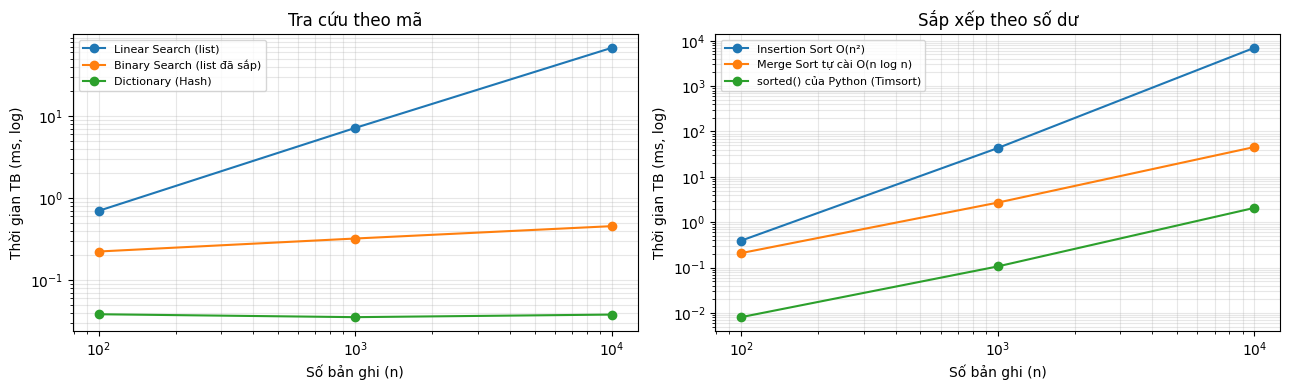

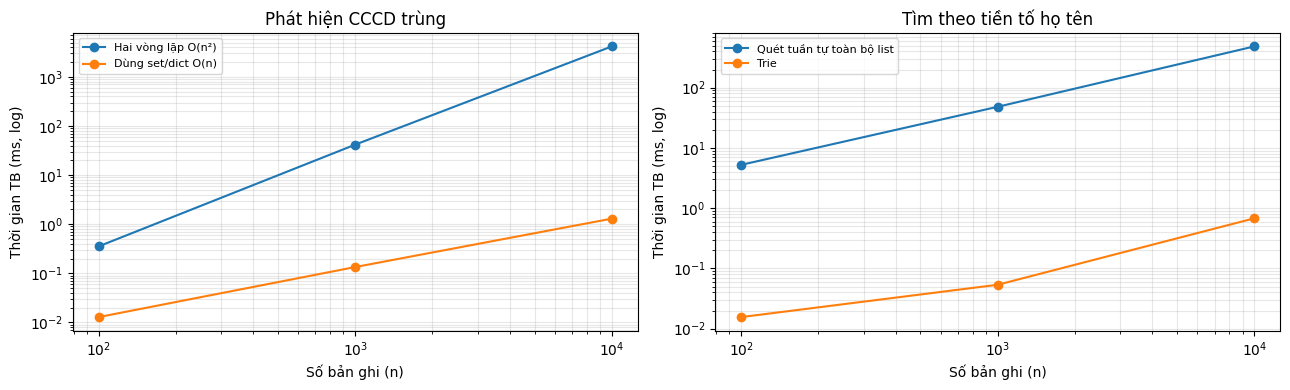

In [10]:
# @title
import matplotlib.pyplot as plt
def ve(nhom_list):
    fig, axes = plt.subplots(1, len(nhom_list), figsize=(13, 4))
    for ax, (k, tt) in zip(axes, nhom_list):
        for p in perf[k][KICH_THUOC[0]]:
            ax.plot(KICH_THUOC, [perf[k][n][p][0]*1000 for n in KICH_THUOC], marker='o', label=p)
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(tt)
        ax.set_xlabel('Số bản ghi (n)'); ax.set_ylabel('Thời gian TB (ms, log)'); ax.grid(True, which='both', alpha=.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
ve([('tra_cuu','Tra cứu theo mã'), ('sap_xep','Sắp xếp theo số dư')])
ve([('trung','Phát hiện CCCD trùng'), ('tien_to','Tìm theo tiền tố họ tên')])

## 6. Menu dòng lệnh (mức 1)
Chạy ô dưới và nhập số để chọn chức năng; nhập `0` để thoát.

In [11]:
ql_demo = nap_he_thong(sinh_du_lieu(1000))   # 1.000 khách hàng mô phỏng
chay_menu(ql_demo)


================= MENU CHƯƠNG TRÌNH =================
1. Thêm khách hàng mới
2. Hiển thị danh sách khách hàng
3. Tìm kiếm khách hàng
4. Sửa hoặc Xóa thông tin khách hàng
5. Sắp xếp danh sách
6. Top-K số dư lớn nhất
7. Thống kê số dư theo nhóm
8. Hoàn tác thao tác vừa rồi (Undo)
9. Ghi / Đọc tệp tin CSV
0. Thoát chương trình

Chọn chức năng: 0
Kết thúc chương trình.
